# Nexar Collision Prediction — Video Inspection

**Computer Vision Project**

## Goal

Inspect the actual Nexar MP4 videos before building the video-processing
and machine-learning pipeline.

This notebook investigates:

- Video duration
- Frames per second (FPS)
- Resolution
- Frame count
- Timestamp-to-frame conversion
- Individual video frames
- Frames around the annotated alert and event times
- Whether the proposed time-to-event (TTE) sampling strategy is practical

We will inspect only a small number of videos.

The full 30 GB dataset will **not** be loaded into memory or processed
in this notebook.


## 1. Imports

We use:

- `pandas` for the training metadata
- `matplotlib` for displaying video frames
- `cv2` (OpenCV) for reading MP4 files
- `Path` for handling file paths


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

from pathlib import Path


What is OpenCV?

OpenCV is a computer-vision library.

In this project, we'll primarily use it to:

MP4 video
    ↓
OpenCV
    ↓
individual frames
    ↓
NumPy arrays
    ↓
CNN / optical flow / temporal model

A video is essentially a sequence of images.

For example, a 30 FPS video contains approximately:

$$ 30\text{ frames per second} $$

So a 40-second video contains roughly:

$$ 40\times30=1200 $$

frames.


In [4]:

DATA_DIR = Path("./data/raw")

TRAIN_DIR = DATA_DIR / "train"

print("Dataset directory:")
print(DATA_DIR.resolve())

print("\nTraining video directory:")
print(TRAIN_DIR.resolve())


Dataset directory:
/Users/rameez/Documents/Wits Stuff/Honours/Computer Vision/nexar-collision-prediction/data/raw

Training video directory:
/Users/rameez/Documents/Wits Stuff/Honours/Computer Vision/nexar-collision-prediction/data/raw/train


## 2. Load the Training Metadata

We need the metadata because it tells us where the collision/near-miss
event and alert occur within each positive video.

We will use the same `train.csv` that was examined in Notebook 1.


In [5]:
train_csv = DATA_DIR / "train.csv"

df = pd.read_csv(train_csv)

df.head()


,id,time_of_event,time_of_alert,target
0,1924,NaN,NaN,0
1,822,19.5,18.633,1
2,1429,NaN,NaN,0
3,208,19.8,19.233,1
4,1904,NaN,NaN,0


## 3. Select a Positive Video

For our first inspection, we want a positive example because positive
videos contain both:

- `time_of_event`
- `time_of_alert`

This allows us to investigate whether the timestamps correspond to
meaningful locations within the actual video.


In [6]:
positive = df[df["target"] == 1].copy()

positive.head()


,id,time_of_event,time_of_alert,target
1,822,19.500,18.633,1
3,208,19.800,19.233,1
5,72,20.101,20.068,1
8,128,19.267,18.333,1
10,205,21.146,18.196,1


In [7]:
sample_row = positive.iloc[0]

print(sample_row)


id               822.000
time_of_event     19.500
time_of_alert     18.633
target             1.000
Name: 1, dtype: float64


You should see information similar to:

id                 1
time_of_event     19.500
time_of_alert     18.633
target              1

Your exact first row should correspond to the data you inspected in Notebook 1.


In [8]:
video_id = int(sample_row["id"])

video_path = TRAIN_DIR / f"{video_id:05d}.mp4"

print("Video ID:", video_id)
print("Video path:", video_path)
print("Exists:", video_path.exists())


Video ID: 822
Video path: data/raw/train/00822.mp4
Exists: True


## 4. Open the Video

OpenCV's `VideoCapture` allows us to read a video file.

We will not read every frame yet.

First, we will ask OpenCV for information about the video itself.


In [9]:
cap = cv2.VideoCapture(str(video_path))

print("Video opened:", cap.isOpened())


Video opened: True


## 5. Inspect Video Properties

OpenCV stores several useful properties about a video.

We are interested in:

- FPS
- Frame count
- Width
- Height
- Duration

These properties will help us understand how timestamps correspond to
individual frames.


In [10]:
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps

print("FPS:", fps)
print("Frame count:", frame_count)
print("Width:", width)
print("Height:", height)
print("Duration:", duration, "seconds")


FPS: 30.0
Frame count: 1214
Width: 1280
Height: 720
Duration: 40.46666666666667 seconds


In [11]:
print("Frame count / FPS:", frame_count / fps)
print("Reported duration:", cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)


Frame count / FPS: 40.46666666666667
Reported duration: 0.0


## 6. Read a Single Frame

A video is a sequence of frames.

We will now read the first frame to confirm that OpenCV can successfully
decode the video.


In [12]:
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

success, frame = cap.read()

print("Frame successfully read:", success)

if success:
    print("Frame shape:", frame.shape)


Frame successfully read: True
Frame shape: (720, 1280, 3)


Why does the shape say (720, 1280, 3)?

An image is represented as:

(height, width, channels)

So:

720 = height
1280 = width
3 = colour channels

The three channels are normally:

Blue
Green
Red

because OpenCV uses BGR ordering rather than the more common RGB ordering.


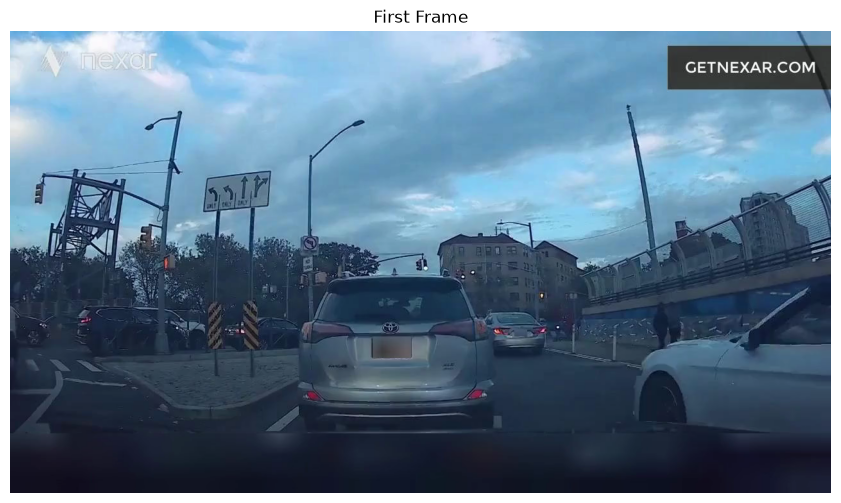

In [13]:
if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.title("First Frame")
    plt.show()


This is our first actual visual inspection of the Nexar footage.


## 7. Read a Frame at a Specific Timestamp

Our research question depends on knowing what the video looks like at
specific times.

OpenCV allows us to seek to a particular frame.

If:

    FPS = 30

then approximately:

    frame_number = timestamp × FPS

For example, at 10 seconds:

    10 × 30 = 300


In [14]:
def read_frame_at_time(video_path, time_seconds):
    cap = cv2.VideoCapture(str(video_path))
    
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_number = int(time_seconds * fps)
    
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    
    success, frame = cap.read()
    
    cap.release()
    
    if not success:
        return None
    
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    return frame_rgb


Why are we creating a function?

Instead of repeatedly writing:

open video
calculate frame
seek
read
convert
close

we can simply do:

frame = read_frame_at_time(video_path, 10)

This function will become useful later when we investigate event-relative frames.


(720, 1280, 3)


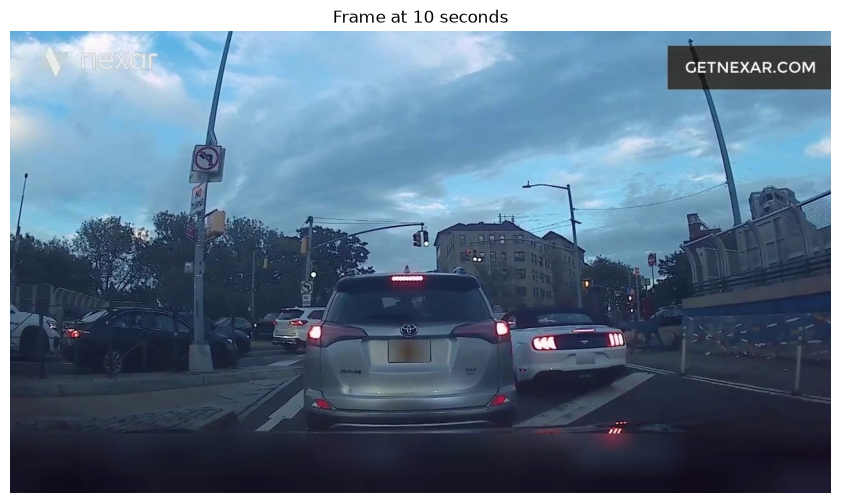

In [15]:
frame_10s = read_frame_at_time(video_path, 10)

print(frame_10s.shape)

plt.figure(figsize=(12, 6))
plt.imshow(frame_10s)
plt.axis("off")
plt.title("Frame at 10 seconds")
plt.show()


## 8. Inspect the Annotated Alert and Event

The positive video's metadata gives us:

- `time_of_alert`
- `time_of_event`

We will now extract frames at both timestamps.

This is an important sanity check.

We want to understand what the footage looks like at the annotated
locations before designing the TTE extraction pipeline.


In [16]:
time_of_alert = sample_row["time_of_alert"]
time_of_event = sample_row["time_of_event"]

print("Time of alert:", time_of_alert)
print("Time of event:", time_of_event)
print("Alert lead time:", time_of_event - time_of_alert)


Time of alert: 18.633
Time of event: 19.5
Alert lead time: 0.8670000000000009


In [17]:
alert_frame = read_frame_at_time(
    video_path,
    time_of_alert
)

event_frame = read_frame_at_time(
    video_path,
    time_of_event
)


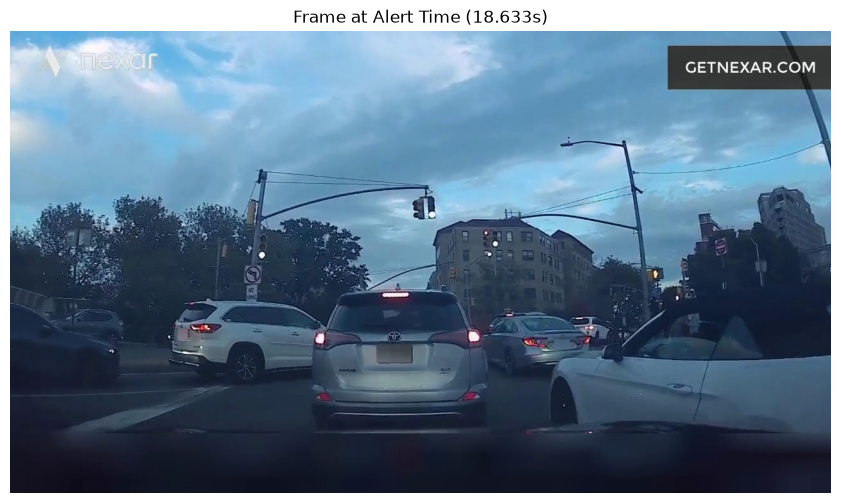

In [18]:
plt.figure(figsize=(12, 6))

plt.imshow(alert_frame)

plt.axis("off")
plt.title(f"Frame at Alert Time ({time_of_alert:.3f}s)")

plt.show()


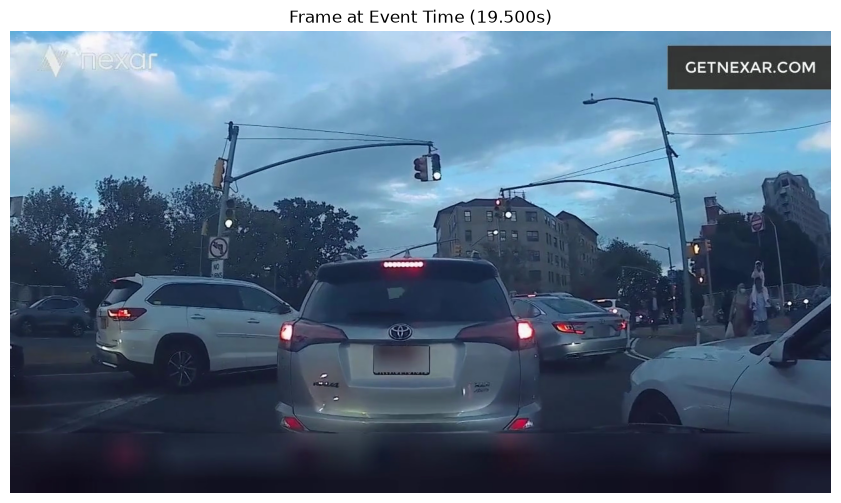

In [19]:
plt.figure(figsize=(12, 6))

plt.imshow(event_frame)

plt.axis("off")
plt.title(f"Frame at Event Time ({time_of_event:.3f}s)")

plt.show()


## 9. Inspect the Proposed TTE Points

Our project investigates prediction at different distances before the
event.

The proposed primary horizons are:

- 0.5 seconds before the event
- 1.0 second before the event
- 1.5 seconds before the event

For a video where:

    time_of_event = 19.5 s

the corresponding prediction points are:

    0.5 s TTE → 19.0 s
    1.0 s TTE → 18.5 s
    1.5 s TTE → 18.0 s

These frames represent the latest information available to the model
before the selected prediction horizon.


In [20]:
tte_values = [0.5, 1.0, 1.5]

for tte in tte_values:
    prediction_time = time_of_event - tte
    
    print(
        f"TTE = {tte:.1f}s -> "
        f"prediction time = {prediction_time:.3f}s"
    )


TTE = 0.5s -> prediction time = 19.000s
TTE = 1.0s -> prediction time = 18.500s
TTE = 1.5s -> prediction time = 18.000s


In [21]:
tte_frames = {}

for tte in tte_values:
    prediction_time = time_of_event - tte
    
    tte_frames[tte] = read_frame_at_time(
        video_path,
        prediction_time
    )


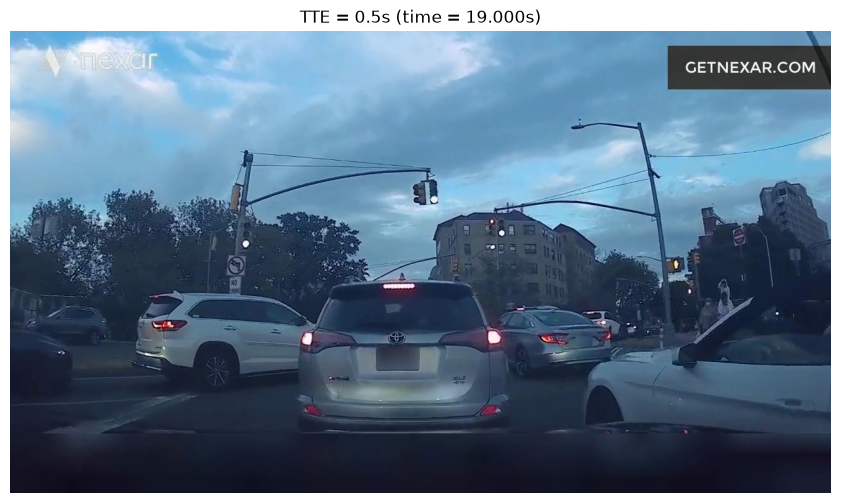

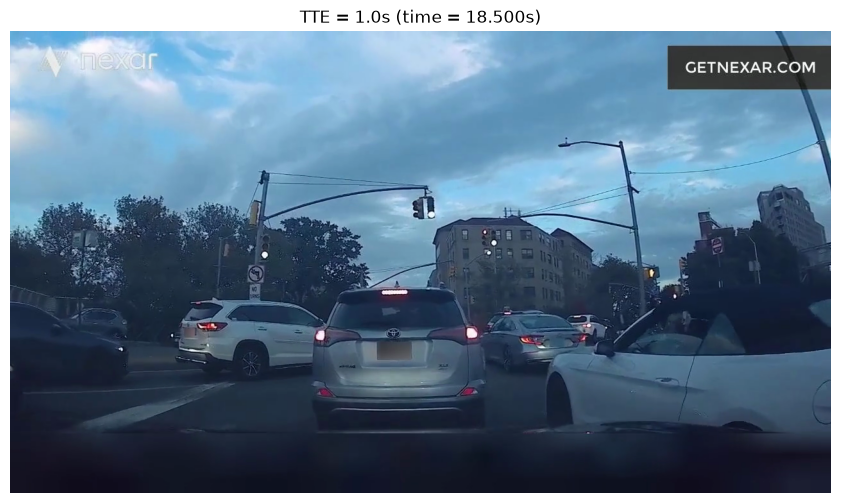

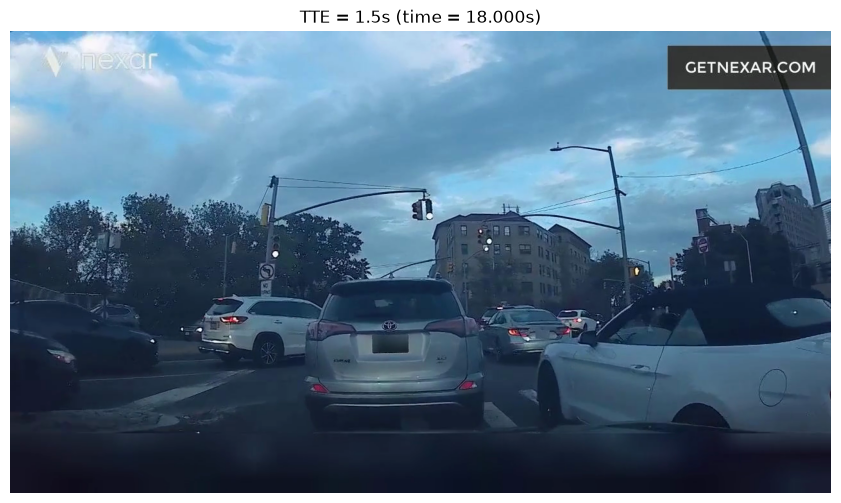

In [22]:
for tte in tte_values:
    plt.figure(figsize=(12, 6))
    
    plt.imshow(tte_frames[tte])
    
    plt.axis("off")
    plt.title(
        f"TTE = {tte:.1f}s "
        f"(time = {time_of_event - tte:.3f}s)"
    )
    
    plt.show()


This is an important visual inspection.

You should be asking:

Is there already visible information suggesting the upcoming event?

But don't draw scientific conclusions from one video. This is just a sanity check.


## 10. Check the Frame Numbers

We can also explicitly calculate which frame corresponds to each TTE.

For a video with FPS `f`:

    frame_number = timestamp × f

We will calculate the frame positions for the event and TTE points.


In [23]:
print("FPS:", fps)

event_frame_number = int(time_of_event * fps)

print(
    "Event frame:",
    event_frame_number
)

for tte in tte_values:
    prediction_time = time_of_event - tte
    frame_number = int(prediction_time * fps)
    
    print(
        f"TTE {tte:.1f}s -> "
        f"time {prediction_time:.3f}s -> "
        f"frame {frame_number}"
    )


FPS: 30.0
Event frame: 585
TTE 0.5s -> time 19.000s -> frame 570
TTE 1.0s -> time 18.500s -> frame 555
TTE 1.5s -> time 18.000s -> frame 540


## 11. Inspect Several Videos

A single video is not enough to understand the dataset.

We will inspect several positive videos to check whether their video
properties are consistent.

We will not process the entire dataset.


In [24]:
sample_positive_ids = positive["id"].head(5).tolist()

print(sample_positive_ids)


[822, 208, 72, 128, 205]


In [25]:
video_information = []

for video_id in sample_positive_ids:
    video_path = TRAIN_DIR / f"{int(video_id):05d}.mp4"
    
    cap = cv2.VideoCapture(str(video_path))
    
    fps_value = cap.get(cv2.CAP_PROP_FPS)
    frame_count_value = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )
    width_value = int(
        cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    )
    height_value = int(
        cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    )
    
    cap.release()
    
    duration_value = frame_count_value / fps_value
    
    video_information.append({
        "id": video_id,
        "fps": fps_value,
        "frames": frame_count_value,
        "width": width_value,
        "height": height_value,
        "duration": duration_value
    })

video_info_df = pd.DataFrame(video_information)

video_info_df


,id,fps,frames,width,height,duration
0,822,30.0,1214,1280,720,40.466667
1,208,30.0,1297,1280,720,43.233333
2,72,30.5,1232,1280,720,40.393443
3,128,30.0,1208,1280,720,40.266667
4,205,30.5,1200,1280,720,39.344262


## 12. Check Video Consistency

We want to determine whether the videos generally use the same FPS and
resolution.

If they do, our later preprocessing pipeline can be simpler.

If they differ, our pipeline will need to account for those differences.


In [26]:
print("FPS values:")
print(video_info_df["fps"].value_counts())

print("\nResolution values:")
print(
    video_info_df[
        ["width", "height"]
    ].value_counts()
)


FPS values:
fps
30.0    3
30.5    2
Name: count, dtype: int64

Resolution values:
width  height
1280   720       5
Name: count, dtype: int64


## 13. Check Whether TTE Points Are Valid

A prediction point must occur after the beginning of the video.

For each positive video, we therefore need:

    time_of_event - TTE > 0

for the selected TTE values.

We will check this across the entire positive dataset.

This does not read the videos; it only uses the metadata.


In [27]:
for tte in tte_values:
    prediction_times = (
        positive["time_of_event"] - tte
    )
    
    invalid = (prediction_times <= 0).sum()
    
    print(
        f"TTE = {tte:.1f}s -> "
        f"{invalid} invalid positive examples"
    )


TTE = 0.5s -> 0 invalid positive examples
TTE = 1.0s -> 0 invalid positive examples
TTE = 1.5s -> 0 invalid positive examples


This is an important check.

For example, if a collision occurs at:

0.3 seconds

then a 1.5-second-before-event observation would be impossible because:

$$ 0.3-1.5=-1.2 $$

There isn't 1.5 seconds of footage before the event.


## 14. Close the Video

We opened the video using OpenCV.

It is good practice to release the video capture object when we are
finished with it.


In [28]:
cap.release()

print("Video capture released.")


Video capture released.


# Video Inspection Summary

## What we investigated

This notebook inspected the actual Nexar MP4 files without processing the
entire 30 GB dataset.

We investigated:

- Video FPS
- Frame count
- Resolution
- Duration
- Individual video frames
- Timestamp-to-frame conversion
- Alert and event frames
- Proposed time-to-event frames
- Consistency across several videos
- Whether the proposed TTE points are valid

## Video representation

A video is represented as a sequence of image frames.

For a video with FPS `f`, a timestamp `t` can approximately be mapped to:

    frame_number = t × f

This allows us to convert the metadata timestamps into specific frames.

## Event-relative sampling

For a positive video with event time `E`, a prediction point at time-to-event
`TTE` is:

    prediction_time = E - TTE

Our primary planned horizons are:

    TTE = 0.5 s
    TTE = 1.0 s
    TTE = 1.5 s

For example, if:

    E = 19.5 s

then:

    0.5 s TTE → 19.0 s
    1.0 s TTE → 18.5 s
    1.5 s TTE → 18.0 s

## Important experimental constraint

Frames after the prediction point must not be provided to the model.

For example, for a 1.5-second TTE experiment:

    event = 19.5 s
    prediction point = 18.0 s

The model must only receive information available at or before 18.0 s.

Frames from 18.0–19.5 seconds must not be used as input for that example.

Otherwise, the experiment would leak information from closer to the
event into a prediction that is supposed to occur 1.5 seconds beforehand.

## Dataset handling

The full 30 GB dataset was not loaded into memory.

Only a small number of videos were inspected.

The original videos remain unchanged in:

    data/raw/train/

## Important observation

The exact FPS, resolution, duration and frame-count behaviour observed in
this notebook should be used when implementing the later video-processing
pipeline rather than assuming video properties from the dataset description.

## Next step

The dataset structure and basic video representation are now understood.

The next notebook should move from inspection to designing the actual
data-sampling pipeline.

The pipeline will need to answer:

1. How many frames should represent each observation?
2. What temporal window should be given to the model?
3. How should positive examples be sampled at each TTE?
4. How should negative examples be sampled so that the comparison is fair?
5. How should train/validation/test splits be created at the video level?
6. How can we avoid temporal and video-level data leakage?

The next stage is therefore:

**Notebook 3 — Dataset Splitting and Temporal Clip Sampling**
